In [1]:
import pandas as pd
import numpy as np
import os
import glob
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

def preprocess_vehicle_dataset(input_file_path, output_file_path, target_hz):
    """
    차량 데이터를 로드하여 Lat/Lon이 유효한 첫 행부터 정제 및 지정된 주파수로 리샘플링을 수행합니다.
    """
    # 10번째 행을 헤더로 로드
    df = pd.read_csv(
        input_file_path, 
        header=9, 
        encoding='cp1252', 
        encoding_errors='replace'
    )
    
    # 1. 필수 컬럼들을 수치형으로 강제 변환 (문자열 등은 NaN 처리)
    cols_to_check = ['latitude', 'longitude', 'time', 'yawAngle', 'yawRate', 
                     'handwheelAngle', 'vxCG', 'vyCG', 'throttle', 'brake', 'axCG', 'ayCG']
    
    for col in cols_to_check:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    
    # 2. latitude와 longitude가 모두 NaN이 아닌 첫 번째 행 인덱스 찾기
    valid_mask = df[['latitude', 'longitude']].notna().all(axis=1)
    if not valid_mask.any():
        return False # 유효한 좌표가 아예 없음
        
    start_idx = valid_mask.idxmax() # 첫 번째 True가 나오는 인덱스
    df = df.iloc[start_idx:].reset_index(drop=True)
    
    # 3. 이후 필수 컬럼에 대해서도 최종 결측치 제거
    df = df.dropna(subset=cols_to_check).reset_index(drop=True)
    
    if df.empty:
        return False

    # 4. 좌표계 변환 및 데이터 구성
    R = 6371000.0
    lat0, lon0 = np.radians(df['latitude'].iloc[0]), np.radians(df['longitude'].iloc[0])
    lat_rad, lon_rad = np.radians(df['latitude']), np.radians(df['longitude'])
    
    X = R * (lon_rad - lon0) * np.cos(lat0)
    Y = R * (lat_rad - lat0)
    
    target_df = pd.DataFrame({
        'time': df['time'], 'X': X, 'Y': Y,
        # np.unwrap을 사용하여 pi -> -pi로 튀는 구간을 연속적으로 연결
        'psi': np.unwrap(np.radians(df['yawAngle']))+np.pi/2,
        'vx': df['vxCG'], 'vy': df['vyCG'],
        'dpsi': np.radians(df['yawRate']),
        'Throttle': df['throttle']/100, 'Brake': df['brake']/100,
        'delta': np.radians(df['handwheelAngle'] / 13.71),
        'ax': df['axCG'], 'ay': df['ayCG']
    })
    
    # 5. 지정된 주파수(Hz)로 리샘플링
    dt = 1.0 / target_hz
    time_resampled = np.arange(target_df['time'].min(), target_df['time'].max(), dt)
    resampled_data = {'time': time_resampled}
    
    for col in target_df.columns:
        if col != 'time':
            interpolator = interp1d(target_df['time'], target_df[col], kind='linear', fill_value="extrapolate")
            resampled_data[col] = interpolator(time_resampled)
            
    pd.DataFrame(resampled_data).to_csv(output_file_path, index=False)
    return True

def batch_process_folder(input_folder, output_folder, target_hz):
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)
        
    csv_files = glob.glob(os.path.join(input_folder, "*.csv"))
    print(f"총 {len(csv_files)}개의 파일을 발견했습니다. (목표 주파수: {target_hz}Hz)")
    
    processed_files = [] # 처리 성공한 파일 경로 저장용
    
    for file_path in csv_files:
        file_name = os.path.basename(file_path)
        output_name = file_name.replace(".csv", f"_{target_hz}hz.csv")
        output_path = os.path.join(output_folder, output_name)
        
        print(f"처리 중: {file_name} ...")
        try:
            if preprocess_vehicle_dataset(file_path, output_path, target_hz):
                print(f"성공: {output_path}")
                processed_files.append(output_path)
            else:
                print(f"건너뜀: {file_name} (유효 데이터 없음)")
        except Exception as e:
            print(f"오류 발생 ({file_name}): {e}")
            
    return processed_files


if __name__ == "__main__":
    input_dir = "C:/workspace/data"
    output_dir = "C:/workspace/processed_data_25hz"
    target_hz = 25 # 파라미터로 원하는 주파수 설정
    
    # 1. 폴더 내 파일 일괄 처리
    processed_list = batch_process_folder(input_dir, output_dir, target_hz)


총 13개의 파일을 발견했습니다. (목표 주파수: 25Hz)
처리 중: 20130222_01_01_03_grandsport.csv ...


C:\Users\mumu2\AppData\Local\Temp\ipykernel_23120\461266357.py:13: DtypeWarning: Columns (0: time, 1: handwheelAngle, 2: throttle, 3: brake, 4: clutch, 5: engineSpeed, 6: PPS, 7: gpsTime, 8: latitude, 9: longitude, 10: altitude, 11: vNorth, 12: vEast, 13: vUp, 14: horizontalSpeed, 15: vxCG, 16: vyCG, 17: vzCG, 18: axCG, 19: ayCG, 20: azCG, 21: yawAngle, 22: pitchAngle, 23: rollAngle, 24: rollRate, 25: pitchRate, 26: yawRate, 27: sideSlip, 28: distance, 29: posAccuracy_north, 30: posAccuracy_east, 31: posAccuracy_down, 32: velAccuracy_north, 33: velAccuracy_east, 34: velAccuracy_down, 35: orientAccuracy_heading, 36: orientAccuracy_pitch, 37: orientAccuracy_roll, 38: chassisAccelFL, 39: chassisAccelFR, 40: chassisAccelRL, 41: chassisAccelRR, 42: deflectionFL, 43: deflectionFR, 44: deflectionRL, 45: deflectionRR, 46: wheelAccelFL, 47: wheelAccelFR, 48: wheelAccelRL, 49: wheelAccelRR) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


성공: C:/workspace/processed_data_25hz\20130222_01_01_03_grandsport_25hz.csv
처리 중: 20130222_01_02_03_grandsport.csv ...


C:\Users\mumu2\AppData\Local\Temp\ipykernel_23120\461266357.py:13: DtypeWarning: Columns (0: time, 1: handwheelAngle, 2: throttle, 3: brake, 4: clutch, 5: engineSpeed, 6: PPS, 7: gpsTime, 8: latitude, 9: longitude, 10: altitude, 11: vNorth, 12: vEast, 13: vUp, 14: horizontalSpeed, 15: vxCG, 16: vyCG, 17: vzCG, 18: axCG, 19: ayCG, 20: azCG, 21: yawAngle, 22: pitchAngle, 23: rollAngle, 24: rollRate, 25: pitchRate, 26: yawRate, 27: sideSlip, 28: distance, 29: posAccuracy_north, 30: posAccuracy_east, 31: posAccuracy_down, 32: velAccuracy_north, 33: velAccuracy_east, 34: velAccuracy_down, 35: orientAccuracy_heading, 36: orientAccuracy_pitch, 37: orientAccuracy_roll, 38: chassisAccelFL, 39: chassisAccelFR, 40: chassisAccelRL, 41: chassisAccelRR, 42: deflectionFL, 43: deflectionFR, 44: deflectionRL, 45: deflectionRR, 46: wheelAccelFL, 47: wheelAccelFR, 48: wheelAccelRL, 49: wheelAccelRR) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


성공: C:/workspace/processed_data_25hz\20130222_01_02_03_grandsport_25hz.csv
처리 중: 20130222_02_01_03_grandsport.csv ...


...

성공: C:/workspace/processed_data_25hz\20130816_01_01_02_grandsport_25hz.csv
처리 중: 20130817_01_01_02_grandsport.csv ...


C:\Users\mumu2\AppData\Local\Temp\ipykernel_23120\461266357.py:13: DtypeWarning: Columns (0: time, 1: handwheelAngle, 2: throttle, 3: brake, 4: clutch, 5: engineSpeed, 6: PPS, 7: gpsTime, 8: latitude, 9: longitude, 10: altitude, 11: vNorth, 12: vEast, 13: vUp, 14: horizontalSpeed, 15: vxCG, 16: vyCG, 17: vzCG, 18: axCG, 19: ayCG, 20: azCG, 21: yawAngle, 22: pitchAngle, 23: rollAngle, 24: rollRate, 25: pitchRate, 26: yawRate, 27: sideSlip, 28: distance, 29: posAccuracy_north, 30: posAccuracy_east, 31: posAccuracy_down, 32: velAccuracy_north, 33: velAccuracy_east, 34: velAccuracy_down, 35: orientAccuracy_heading, 36: orientAccuracy_pitch, 37: orientAccuracy_roll, 38: chassisAccelFL, 39: chassisAccelFR, 40: chassisAccelRL, 41: chassisAccelRR, 42: deflectionFL, 43: deflectionFR, 44: deflectionRL, 45: deflectionRR, 46: wheelAccelFL, 47: wheelAccelFR, 48: wheelAccelRL, 49: wheelAccelRR) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


성공: C:/workspace/processed_data_25hz\20130817_01_01_02_grandsport_25hz.csv
처리 중: 20130817_02_01_02_grandsport.csv ...


C:\Users\mumu2\AppData\Local\Temp\ipykernel_23120\461266357.py:13: DtypeWarning: Columns (0: time, 1: handwheelAngle, 2: throttle, 3: brake, 4: clutch, 5: engineSpeed, 6: PPS, 7: gpsTime, 8: latitude, 9: longitude, 10: altitude, 11: vNorth, 12: vEast, 13: vUp, 14: horizontalSpeed, 15: vxCG, 16: vyCG, 17: vzCG, 18: axCG, 19: ayCG, 20: azCG, 21: yawAngle, 22: pitchAngle, 23: rollAngle, 24: rollRate, 25: pitchRate, 26: yawRate, 27: sideSlip, 28: distance, 29: posAccuracy_north, 30: posAccuracy_east, 31: posAccuracy_down, 32: velAccuracy_north, 33: velAccuracy_east, 34: velAccuracy_down, 35: orientAccuracy_heading, 36: orientAccuracy_pitch, 37: orientAccuracy_roll, 38: chassisAccelFL, 39: chassisAccelFR, 40: chassisAccelRL, 41: chassisAccelRR, 42: deflectionFL, 43: deflectionFR, 44: deflectionRL, 45: deflectionRR, 46: wheelAccelFL, 47: wheelAccelFR, 48: wheelAccelRL, 49: wheelAccelRR) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


성공: C:/workspace/processed_data_25hz\20130817_02_01_02_grandsport_25hz.csv



검증을 위해 첫 번째 파일의 그래프를 그립니다...


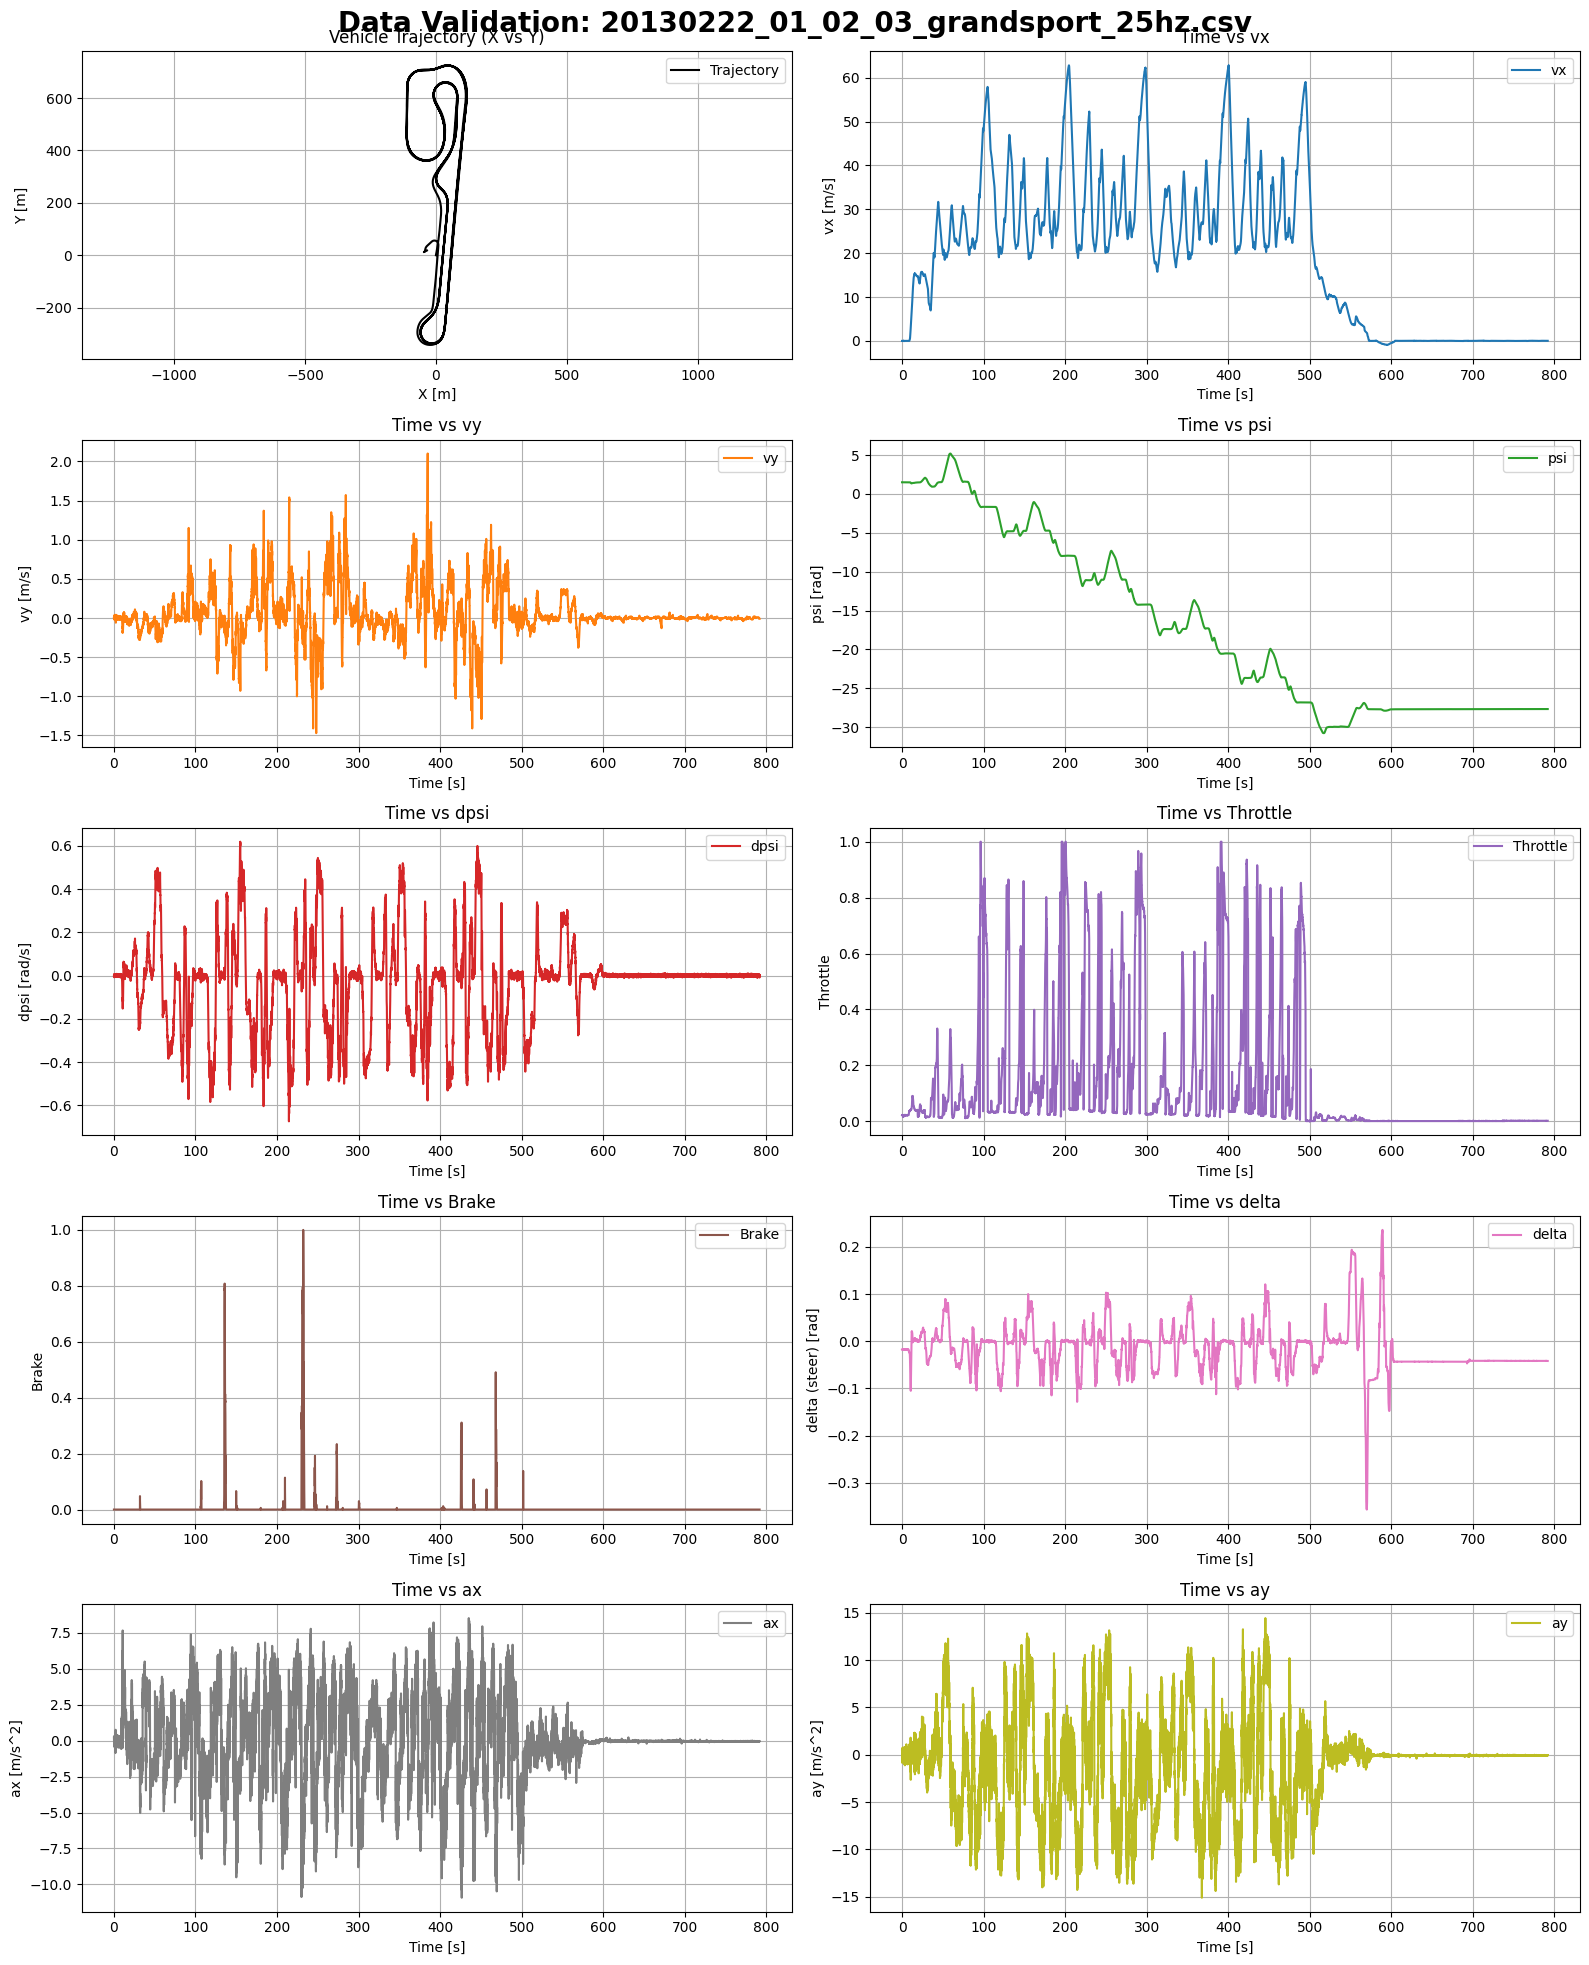

In [2]:
def plot_validation(csv_path):
    """
    정제된 CSV 파일을 로드하여 X-Y 경로 및 주요 물리량의 시간 트렌드를 각각의 그래프로 출력합니다.
    """
    df = pd.read_csv(csv_path)
    time = df['time']
    
    # 총 10개의 플롯(궤적 1개 + 시계열 9개)을 위한 5행 2열 레이아웃
    fig, axs = plt.subplots(5, 2, figsize=(16, 20))
    axs = axs.flatten() # 2D 배열을 1D로 펴서 인덱싱을 쉽게 함
    
    # 1. Position (X-Y 궤적 그래프)
    axs[0].plot(df['X'], df['Y'], label='Trajectory', color='black', linewidth=1.5)
    axs[0].set_xlabel('X [m]')
    axs[0].set_ylabel('Y [m]')
    axs[0].set_title('Vehicle Trajectory (X vs Y)')
    axs[0].axis('equal') # 실제 경로 비율(1:1)이 왜곡되지 않도록 설정
    axs[0].grid(True)
    axs[0].legend(loc='upper right')
    
    # 2. 개별 시계열 그래프 설정 (변수명, Y축 라벨, 색상)
    variables = ['vx', 'vy', 'psi', 'dpsi', 'Throttle', 'Brake', 'delta', 'ax', 'ay']
    y_labels = [
        'vx [m/s]', 'vy [m/s]', 'psi [rad]', 'dpsi [rad/s]', 
        'Throttle', 'Brake', 'delta (steer) [rad]', 'ax [m/s^2]', 'ay [m/s^2]'
    ]
    colors = [
        'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 
        'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive'
    ]
    
    # 반복문을 통해 나머지 9개의 그래프 생성
    for i, var in enumerate(variables):
        idx = i + 1 # 0번 인덱스는 X-Y 궤적이 차지했으므로 +1
        
        axs[idx].plot(time, df[var], label=var, color=colors[i])
        axs[idx].set_xlabel('Time [s]')
        axs[idx].set_ylabel(y_labels[i])
        axs[idx].set_title(f'Time vs {var}')
        axs[idx].grid(True)
        axs[idx].legend(loc='upper right')
    
    plt.suptitle(f"Data Validation: {os.path.basename(csv_path)}", fontsize=20, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

if processed_list:
    print("\n검증을 위해 첫 번째 파일의 그래프를 그립니다...")
    plot_validation(processed_list[1])
else:
    print("\n처리된 파일이 없어 그래프를 그릴 수 없습니다.")

In [17]:
import os
import glob
import torch
import pandas as pd
import numpy as np
from tqdm import tqdm

# --- 차량 제원 및 물리 상수 ---
m = 1014.0
lf = 1.2
lr = 1.29
dt = 0.04

# --- 좌표 변환 헬퍼 함수 ---
def global_to_local_numpy(positions, ref_pos):
    dx = positions[..., 0] - ref_pos[..., 0]
    dy = positions[..., 1] - ref_pos[..., 1]
    dpsi = positions[..., 2] - ref_pos[..., 2] 
    
    psi_std = ref_pos[..., 2]
    cos_p = np.cos(psi_std)
    sin_p = np.sin(psi_std)
    
    loc_x = dx * cos_p + dy * sin_p
    loc_y = -dx * sin_p + dy * cos_p
    return np.stack((loc_x, loc_y, dpsi), axis=-1)

# --- 1. 파일 목록 확보 ---
folders = ["C:/workspace/processed_data_25hz"]
all_files = []
for f in folders: 
    all_files.extend(glob.glob(os.path.join(f, "*.csv")))

seq_len = 4
stride = 1

# 🌟 원하는 Horizon 스텝 설정 (4든 8이든 여기만 바꾸면 연동됩니다)
num_steps = 25
lookahead_margin = num_steps + 1  

# --- 2. 통계량(mean, std) 계산 ---
all_samples, all_accels = [], []

print("슬라이딩 윈도우 기반 글로벌 표준화 파라미터 계산 중...")
for f in tqdm(all_files, desc="통계량 산출 CSV 분석"):
    df = pd.read_csv(f)
    states = df[['vx', 'vy', 'dpsi']].values
    ctrls = df[['Throttle', 'Brake', 'delta']].values
    positions = df[['X', 'Y', 'psi']].values
    accels = df[['ax', 'ay']].values
    
    for start_idx in range(0, len(states) - seq_len - lookahead_margin, stride):
        seq_pos = positions[start_idx : start_idx + seq_len]
        mid_idx = seq_len // 2
        ref_pos = seq_pos[mid_idx]
        
        loc_pos = global_to_local_numpy(seq_pos, ref_pos)
        sample = np.hstack((loc_pos, states[start_idx : start_idx + seq_len], ctrls[start_idx : start_idx + seq_len]))
        all_samples.append(sample)
        all_accels.append(accels[start_idx : start_idx + seq_len])
        
concat_inp = np.vstack(all_samples)
concat_acc = np.vstack(all_accels)

global_stats = {
    'in_mean': concat_inp.mean(axis=0), 
    'in_std': concat_inp.std(axis=0),
    'accel_std': concat_acc.std(axis=0)
}
print("글로벌 데이터 통계량 계산 완료.")

# --- 3. 로컬 텐서 리스트 채우기 ---
in_mean_t = torch.tensor(global_stats['in_mean'], dtype=torch.float32)
in_std_t = torch.tensor(global_stats['in_std'], dtype=torch.float32)

all_processed_inputs, all_curr_raw, all_ctrl, all_accel = [], [], [], []

# 동적 저장을 위한 딕셔너리 컨테이너
target_containers = {f't{i}': [] for i in range(1, num_steps + 1)}          
ctrl_containers = {f'ctrl_t{i}': [] for i in range(1, num_steps)}          
all_final_pos = []                                                            

all_ref_pos = []         
all_curr_global_pos = [] 

def local_transform(pos, r_pos):
    dx = pos[..., 0] - r_pos[..., 0]
    dy = pos[..., 1] - r_pos[..., 1]
    dpsi = pos[..., 2] - r_pos[..., 2]
    
    psi_std = r_pos[..., 2]
    cos_p = torch.cos(psi_std)
    sin_p = torch.sin(psi_std)
    
    return torch.stack((dx * cos_p + dy * sin_p, -dx * sin_p + dy * cos_p, dpsi), dim=-1)

for f in tqdm(all_files, desc="최종 데이터셋 텐서 빌드 및 정규화"):
    df = pd.read_csv(f)
    states = torch.tensor(df[['vx', 'vy', 'dpsi']].values, dtype=torch.float32)
    accels = torch.tensor(df[['ax', 'ay']].values, dtype=torch.float32)
    positions = torch.tensor(df[['X', 'Y', 'psi']].values, dtype=torch.float32)
    ctrl_inputs = torch.tensor(df[['Throttle', 'Brake', 'delta']].values, dtype=torch.float32)

    for start_idx in range(0, len(states) - seq_len - lookahead_margin, stride):
        curr_idx = start_idx + seq_len - 1
        mid_idx = start_idx + seq_len // 2
        
        ref_pos = positions[mid_idx]
        curr_global_pos = positions[curr_idx] 
        
        loc_pos_seq = local_transform(positions[start_idx : start_idx + seq_len], ref_pos)
        
        in_unnorm = torch.cat([loc_pos_seq, states[start_idx : start_idx + seq_len], ctrl_inputs[start_idx : start_idx + seq_len]], dim=1)
        all_processed_inputs.append((in_unnorm - in_mean_t) / (in_std_t + 1e-6))
        
        curr_pos_loc = local_transform(positions[curr_idx], ref_pos)
        all_curr_raw.append(torch.cat([states[curr_idx], curr_pos_loc]))
        all_ctrl.append(ctrl_inputs[curr_idx])
        all_accel.append(accels[curr_idx])
        
        for i in range(1, num_steps + 1):
            ti_pos_loc = local_transform(positions[curr_idx + i], ref_pos)
            target_containers[f't{i}'].append(
                torch.cat([states[curr_idx + i], ti_pos_loc, accels[curr_idx + i]])
            )
            
        for i in range(1, num_steps):
            ctrl_containers[f'ctrl_t{i}'].append(ctrl_inputs[curr_idx + i])
            
        # 🎯 최외각 시점의 위치 정보
        final_pos_loc = local_transform(positions[curr_idx + lookahead_margin], ref_pos)
        all_final_pos.append(final_pos_loc)
        
        all_ref_pos.append(ref_pos)
        all_curr_global_pos.append(curr_global_pos)

# --- 4. 딕셔너리로 저장 ---
dataset_dict = {
    'processed_inputs': torch.stack(all_processed_inputs),
    'curr_raw': torch.stack(all_curr_raw),
    'ctrl': torch.stack(all_ctrl),
    'accel': torch.stack(all_accel),
    f't{num_steps+1}_pos': torch.stack(all_final_pos),  # 🌟 키 이름을 동적으로 매핑 (ex: t5_pos)
    'ref_pos': torch.stack(all_ref_pos),                  
    'curr_global_pos': torch.stack(all_curr_global_pos),  
    'global_stats': global_stats          
}

for k, v in target_containers.items():
    dataset_dict[k] = torch.stack(v)
for k, v in ctrl_containers.items():
    dataset_dict[k] = torch.stack(v)

torch.save(dataset_dict, 'processed_dataset_25hz_sl4.pt')
print(f"🎉 모든 전처리 완료 및 'processed_dataset.pt' 저장 성공! (Horizon: {num_steps} Steps 대응)")

슬라이딩 윈도우 기반 글로벌 표준화 파라미터 계산 중...


통계량 산출 CSV 분석: 100%|██████████| 8/8 [00:04<00:00,  1.95it/s]


글로벌 데이터 통계량 계산 완료.


최종 데이터셋 텐서 빌드 및 정규화: 100%|██████████| 8/8 [06:18<00:00, 47.26s/it]


🎉 모든 전처리 완료 및 'processed_dataset.pt' 저장 성공! (Horizon: 25 Steps 대응)


In [13]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
import scipy.io as sio
import numpy as np

# --- 전역 상수 정의 ---
max_num_steps = 25 
m = 1014
lf = 1.2
lr = 1.29
dt = 0.04

# --- 🎯 하이퍼파라미터 설정 (수정 가능) ---
# 실험 시 사용하는 모든 변수를 영구적으로 관리하고 저장하기 위해 딕셔너리로 구성합니다.
HYPERPARAMS = {
    "max_train_horizon": 25,
    "total_epochs": 250,
    "seq_len": 16,                # 예: 12 또는 16
    "learning_rate": 4.169769727572758E-4,
    "hidden_dim": 256,            # 예: 128 또는 256
    "num_layers": 5,              # GRU 레이어 수
    "num_fc_layers": 2,           # FC 레이어 수
    "dropout_rate": 0.2551,
    "act_func": "tanh",           # "relu", "tanh", "gelu"
    "batch_size": 2048,
    "scheduler_patience":5,
    "scheduler_factor": 0.3341
}

# 디스크 I/O 병목을 방지하기 위한 전역 데이터 캐시 딕셔너리
DATA_CACHE = {}

def get_data_dict(seq_len):
    if seq_len not in DATA_CACHE:
        # 1. Kaggle 읽기 전용 입력 경로로 수정
        file_name = f'C:/workspace/processed_dataset_25hz_sl{seq_len}.pt'
        if not os.path.exists(file_name):
            raise FileNotFoundError(f"필요한 데이터셋 파일이 경로에 없습니다: {file_name}")
        DATA_CACHE[seq_len] = torch.load(file_name, map_location='cpu', weights_only=False)
    return DATA_CACHE[seq_len]

# --- 1. 가변 Horizon 동적 빌드형 Dataset ---
class PreProcessedVehicleDataset(Dataset):
    def __init__(self, data_dict):
        self.max_num_steps = max_num_steps
        
        self.processed_inputs = data_dict['processed_inputs'].clone().detach().float()
        self.curr_raw = data_dict['curr_raw'].clone().detach().float()
        self.ctrl = data_dict['ctrl'].clone().detach().float()
        self.accel = data_dict['accel'].clone().detach().float()
        self.ref_pos = data_dict['ref_pos'].clone().detach().float()
        self.curr_global_pos = data_dict['curr_global_pos'].clone().detach().float()
        
        targets_list = []
        for i in range(1, self.max_num_steps + 1):
            targets_list.append(data_dict[f't{i}'].clone().detach().float())
        self.future_targets = torch.stack(targets_list, dim=1) 
        
        final_pos_key = f't{self.max_num_steps+1}_pos'
        if final_pos_key in data_dict:
            self.final_pos = data_dict[final_pos_key].clone().detach().float()
        else:
            final_data_key = f't{self.max_num_steps+1}'
            if final_data_key in data_dict:
                self.final_pos = data_dict[final_data_key].clone().detach().float()[:, 3:6]
            else:
                self.final_pos = data_dict[f't{self.max_num_steps}'].clone().detach().float()[:, 3:6]
            
        if self.max_num_steps > 1:
            ctrls_list = []
            for i in range(1, self.max_num_steps):
                ctrls_list.append(data_dict[f'ctrl_t{i}'].clone().detach().float())
            self.future_ctrls = torch.stack(ctrls_list, dim=1) 
        else:
            self.future_ctrls = torch.empty(len(self.processed_inputs), 0, 3)

    def __len__(self): 
        return len(self.processed_inputs)
        
    def __getitem__(self, idx):
        return (self.processed_inputs[idx], self.curr_raw[idx], self.ctrl[idx], self.accel[idx], 
                self.future_targets[idx], self.final_pos[idx], self.future_ctrls[idx], 
                self.ref_pos[idx], self.curr_global_pos[idx])

# --- 2. 좌표 변환 (Tensor) ---
def global_to_local_torch(positions, ref_pos):
    dx = positions[..., 0] - ref_pos[..., 0]
    dy = positions[..., 1] - ref_pos[..., 1]
    dpsi = positions[..., 2] - ref_pos[..., 2]
    
    psi_std = ref_pos[..., 2]
    cos_p = torch.cos(psi_std)
    sin_p = torch.sin(psi_std)
    return torch.stack((dx * cos_p + dy * sin_p, -dx * sin_p + dy * cos_p, dpsi), dim=-1)

# --- 3. 네트워크 모델 ---
class DeepDynamicsModel(nn.Module):
    ACT_MAP = {
        'relu': nn.ReLU(),
        'tanh': nn.Tanh(),
        'gelu': nn.GELU()
    }
    
    def __init__(self, input_dim=9, hidden_dim=512, num_layers=1, num_fc_layers=1, dropout_rate=0.1, act_func='tanh'):
        super(DeepDynamicsModel, self).__init__()
        
        self.act = self.ACT_MAP[act_func]
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        
        layers = [nn.Linear(hidden_dim, hidden_dim), self.act, nn.Dropout(dropout_rate)]
        for _ in range(num_fc_layers):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(self.act)
            layers.append(nn.Dropout(dropout_rate))
            
        self.mlp_backbone = nn.Sequential(*layers)
        self.output_layer = nn.Linear(hidden_dim, 18)
        self.sigmoid = nn.Sigmoid()
        
        self.register_buffer('t_min', torch.tensor([1, 0.5, 500, -3.0, -0.1, -400.0]))
        self.register_buffer('t_max', torch.tensor([30, 2.2, 20000.0, 0, 0.1, 400.0]))
        self.register_buffer('dr_min', torch.tensor([500, 0.0, 150.0, 0.2, 500]))
        self.register_buffer('dr_max', torch.tensor([20000.0, 1.5, 2000.0, 2, 20000]))
        self.register_buffer('Iz_min', torch.tensor([500.0]))
        self.register_buffer('Iz_max', torch.tensor([2000.0]))
        
    def forward(self, input_seq, h_0=None):
        _, h_n = self.gru(input_seq, h_0)
        x = self.mlp_backbone(h_n[-1])
        out = self.sigmoid(self.output_layer(x))
        tf = self.t_min + (self.t_max - self.t_min) * out[:, 0:6]
        tr = self.t_min + (self.t_max - self.t_min) * out[:, 6:12]
        dr = self.dr_min + (self.dr_max - self.dr_min) * out[:, 12:17]
        Iz = self.Iz_min + (self.Iz_max - self.Iz_min) * out[:, 17:18]
        return tf, tr, dr, Iz, h_n

# --- 4. 물리 기반 역학 스텝 ---
def position_step(state, pos):
    vx, vy, r = state[:, 0], state[:, 1], state[:, 2]
    X, Y, psi = pos[:, 0], pos[:, 1], pos[:, 2]
    
    return torch.stack([X + (vx * torch.cos(psi) - vy * torch.sin(psi)) * dt,
                        Y + (vx * torch.sin(psi) + vy * torch.cos(psi)) * dt,
                        psi + r * dt], dim=1)

def velocity_step(state, ctrl, tf, tr, dr, iz):
    vx, vy, r = state[:, 0], state[:, 1], state[:, 2]
    T, brake, delta = ctrl[:, 0], ctrl[:, 1], ctrl[:, 2]

    Frx = (dr[:, 0] - dr[:, 1] * vx) * T - dr[:,4] * brake - dr[:, 2] - dr[:, 3] * (vx**2)
    af = delta - torch.atan2(r * lf + vy, vx + 1e-6) + tf[:, 4]
    ar = torch.atan2(r * lr - vy, vx + 1e-6) + tr[:, 4]
    Ffy = tf[:, 5] + tf[:, 2] * torch.sin(tf[:, 1] * torch.atan(tf[:, 0]*af - tf[:, 3]*(tf[:, 0]*af - torch.atan(tf[:, 0]*af))))
    Fry = tr[:, 5] + tr[:, 2] * torch.sin(tr[:, 1] * torch.atan(tr[:, 0]*ar - tr[:, 3]*(tr[:, 0]*ar - torch.atan(tr[:, 0]*ar))))
    vx_dot = (- Ffy * torch.sin(delta) + Frx) / m + vy * r
    vy_dot = (Ffy * torch.cos(delta) + Fry) / m - vx * r
    r_dot = (Ffy * torch.cos(delta) * lf - Fry * lr) / (iz.squeeze() + 1e-6)
    return torch.stack([vx + vx_dot * dt, vy + vy_dot * dt, r + r_dot * dt], dim=1), torch.stack([vx_dot - vy * r, vy_dot + vx * r], dim=1)

# --- 5. Loss 계산 모듈 ---
def calculate_physics_loss(model, input_seq, curr_raw, curr_ctrl, curr_accel, 
                           batch_targets, batch_final_pos, batch_future_ctrls, gpu_stats, ref_pos, curr_global_pos, active_num_steps):
    
    s_std = gpu_stats['s_std']
    p_std = gpu_stats['p_std']
    a_std = gpu_stats['a_std']
    state_weights = gpu_stats['state_weights']
    pos_weights = gpu_stats['pos_weights']

    tf, tr, dr, iz, _ = model(input_seq)

    loss_tensors = {}
    st_curr = curr_raw[:, 0:3]
    pos_global_curr = curr_global_pos
    ctrl_curr = curr_ctrl

    for i in range(active_num_steps):
        st_next, acc_curr_p = velocity_step(st_curr, ctrl_curr, tf, tr, dr, iz)
        pos_global_next = position_step(st_curr, pos_global_curr)

        target_accel = curr_accel if i == 0 else batch_targets[:, i-1, 6:8]
        loss_tensors[f'accel_t{i}'] = torch.mean(((acc_curr_p - target_accel) / a_std)**2)

        target_state = batch_targets[:, i, 0:3]
        loss_tensors[f'state_t{i+1}'] = torch.mean((state_weights * (st_next - target_state) / s_std)**2)

        if i > 0:
            pos_local_next = global_to_local_torch(pos_global_next, ref_pos)
            loss_tensors[f'pos_t{i+1}'] = torch.mean((pos_weights * (pos_local_next - batch_targets[:, i, 3:6]) / p_std)**2)

        st_curr = st_next
        pos_global_curr = pos_global_next
        if i < active_num_steps - 1:
            ctrl_curr = batch_future_ctrls[:, i, :]

    pos_global_final = position_step(st_curr, pos_global_curr)
    pos_local_final = global_to_local_torch(pos_global_final, ref_pos)
    
    target_final_pos = batch_targets[:, active_num_steps, 3:6] if active_num_steps < max_num_steps else batch_final_pos
    loss_tensors[f'pos_t{active_num_steps+1}'] = torch.mean((pos_weights * (pos_local_final - target_final_pos) / p_std)**2)

    w_s, w_p, w_a = 1.0, 1.0, 1.0
    total_loss = 0.0

    for i in range(active_num_steps):
        l_s = loss_tensors[f'state_t{i+1}']
        l_a = loss_tensors[f'accel_t{i}']
        l_p = loss_tensors[f'pos_t{i+2}']
        
        # 모든 시점 가중치는 항상 균등하게 1.0 반영
        total_loss += w_s * l_s + w_p * l_p + w_a * l_a

    # 가중치 총합으로 정규화
    total_loss = total_loss / active_num_steps
    metrics = {k: v.item() for k, v in loss_tensors.items()}
    return total_loss, metrics

# --- 메인 실행 모듈 ---
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"현재 연산 장치: {device} | 단일 학습 엔진 초기화 중...")

    # 하이퍼파라미터 변수화
    seq_len = HYPERPARAMS["seq_len"]
    learning_rate = HYPERPARAMS["learning_rate"]
    hidden_dim = HYPERPARAMS["hidden_dim"]
    num_layers = HYPERPARAMS["num_layers"]
    num_fc_layers = HYPERPARAMS["num_fc_layers"]
    dropout_rate = HYPERPARAMS["dropout_rate"]
    act_func = HYPERPARAMS["act_func"]
    batch_size = HYPERPARAMS["batch_size"]
    scheduler_patience = HYPERPARAMS["scheduler_patience"]
    scheduler_factor = HYPERPARAMS["scheduler_factor"]
    total_epochs = HYPERPARAMS["total_epochs"]

    data_dict = get_data_dict(seq_len)
    global_stats = data_dict['global_stats']

    in_std_t = torch.tensor(global_stats['in_std'], device=device).float()
    accel_std_t = torch.tensor(global_stats['accel_std'], device=device).float()

    gpu_stats = {
        's_std': in_std_t[3:6] + 1e-6,
        'p_std': in_std_t[0:3] + 1e-6,
        'a_std': torch.clamp(accel_std_t, min=1.0),
        'state_weights': torch.tensor([1.0, 1.0, 1.0], device=device).float(),
        'pos_weights': torch.tensor([1.0, 1.0, 1.0], device=device).float()
    }

    full_dataset = PreProcessedVehicleDataset(data_dict)
    v_idx = int(len(full_dataset) * 0.8)
    train_dataset = Subset(full_dataset, range(0, v_idx))
    val_dataset = Subset(full_dataset, range(v_idx, len(full_dataset)))

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, pin_memory=True)

    model = DeepDynamicsModel(
        hidden_dim=hidden_dim, 
        num_layers=num_layers,
        num_fc_layers=num_fc_layers,
        dropout_rate=dropout_rate,
        act_func=act_func
    ).to(device)
    
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=scheduler_factor, patience=scheduler_patience
    )

    best_val_loss = float('inf')
    prev_train_steps = 0
    val_loss_history = []

    print(
        f"\n▶ 학습 시작 | 파라미터 세팅:\n"
        f"  ▷ Max Train Horizon=25 (총 {total_epochs} 에폭 고정)\n"
        f"  ▷ SeqLen={seq_len}, LR={learning_rate:.5f}, Hidden={hidden_dim}, GRU={num_layers}, FC={num_fc_layers}, "
        f"Dropout={dropout_rate:.2f}, Act={act_func}\n"
        f"  ▷ Batch={batch_size}, Patience={scheduler_patience}, Factor={scheduler_factor:.2f}"
    )

    for epoch in range(total_epochs):
        display_epoch = epoch + 1
        
        train_active_steps = display_epoch//10 + 4
        
        val_active_steps = 25 

        if train_active_steps != prev_train_steps:
            prev_train_steps = train_active_steps
            print(f"  🔄 [Curriculum] 학습 난이도 상승 ➔ 스텝 {train_active_steps} (에폭 {display_epoch}~)")

        model.train()
        t_loss = 0
        for batch in train_loader:
            i_s, c_r, ct_r, a_r, b_targets, b_final_pos, b_ctrls, ref_pos, curr_global_pos = [b.to(device, non_blocking=True) for b in batch]
            optimizer.zero_grad()
            loss, _ = calculate_physics_loss(model, i_s, c_r, ct_r, a_r, b_targets, b_final_pos, b_ctrls, gpu_stats, ref_pos, curr_global_pos, train_active_steps)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            t_loss += loss.item()

        model.eval()
        v_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                i_s, c_r, ct_r, a_r, b_targets, b_final_pos, b_ctrls, ref_pos, curr_global_pos = [b.to(device, non_blocking=True) for b in batch]
                loss, _ = calculate_physics_loss(model, i_s, c_r, ct_r, a_r, b_targets, b_final_pos, b_ctrls, gpu_stats, ref_pos, curr_global_pos, val_active_steps)
                v_loss += loss.item()
        
        avg_v = v_loss / len(val_loader)
        scheduler.step(avg_v)
        
        val_loss_history.append(avg_v)
        

        print(f"  [Epoch {display_epoch}/{total_epochs}] Train Loss: {t_loss/len(train_loader):.6f} | Val Loss: {avg_v:.6f}")

        # 베스트 모델 갱신 및 저장
        if avg_v < best_val_loss:
            best_val_loss = avg_v
            
            # HYPERPARAMS에 기록된 모든 설정 변수 영구화 병합
            meta_params = {f"opt_{k}": v for k, v in HYPERPARAMS.items()}
            meta_params['val_loss_history'] = np.array(val_loss_history)
            
            mat_filename = f'C:/workspace/tuning_best_model{epoch}.mat'
            
            weights = {k.replace('.', '_'): v.detach().cpu().numpy() for k, v in model.state_dict().items()}
            weights.update({'in_mean': global_stats['in_mean'], 'in_std': global_stats['in_std']})
            weights.update(meta_params)
            sio.savemat(mat_filename, weights)
            
            print(f"  🌟 Best 25-Step Val Loss 달성: {avg_v:.6f} -> '{mat_filename}' 저장 완료!")

    print("\n" + "="*50)
    print("🏆 학습 완료!")
    print(f"가장 낮은 최종(Step 25) Validation Loss: {best_val_loss:.6f}")
    print("="*50)

현재 연산 장치: cuda | 단일 학습 엔진 초기화 중...

▶ 학습 시작 | 파라미터 세팅:
  ▷ Max Train Horizon=25 (총 250 에폭 고정)
  ▷ SeqLen=16, LR=0.00042, Hidden=256, GRU=5, FC=2, Dropout=0.26, Act=tanh
  ▷ Batch=2048, Patience=5, Factor=0.33
  🔄 [Curriculum] 학습 난이도 상승 ➔ 스텝 4 (에폭 1~)
  [Epoch 1/250] Train Loss: 0.343386 | Val Loss: 0.807762
  🌟 Best 25-Step Val Loss 달성: 0.807762 -> 'C:/workspace/tuning_best_model0.mat' 저장 완료!
  [Epoch 2/250] Train Loss: 0.197790 | Val Loss: 0.700834
  🌟 Best 25-Step Val Loss 달성: 0.700834 -> 'C:/workspace/tuning_best_model1.mat' 저장 완료!
  [Epoch 3/250] Train Loss: 0.181137 | Val Loss: 0.787790
  [Epoch 4/250] Train Loss: 0.174683 | Val Loss: 0.724426
  [Epoch 5/250] Train Loss: 0.167584 | Val Loss: 0.673470
  🌟 Best 25-Step Val Loss 달성: 0.673470 -> 'C:/workspace/tuning_best_model4.mat' 저장 완료!
  [Epoch 6/250] Train Loss: 0.165529 | Val Loss: 0.695914
  [Epoch 7/250] Train Loss: 0.161833 | Val Loss: 0.701531
  [Epoch 8/250] Train Loss: 0.160101 | Val Loss: 0.684092
  [Epoch 9/250] Train Lo

KeyboardInterrupt: 

In [ ]:
import os
import glob
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
import scipy.io as sio
from tqdm import tqdm
import numpy as np
import optuna

# --- 전역 상수 정의 ---
max_num_steps = 25 
m = 1014
lf = 1.2
lr = 1.29
dt = 0.04

# 디스크 I/O 병목을 방지하기 위한 전역 데이터 캐시 딕셔너리
DATA_CACHE = {}

def get_data_dict(seq_len):
    if seq_len not in DATA_CACHE:
        # 1. Kaggle 읽기 전용 입력 경로로 수정
        file_name = f'C:/workspace/processed_dataset_25hz_sl{seq_len}.pt'
        if not os.path.exists(file_name):
            raise FileNotFoundError(f"필요한 데이터셋 파일이 경로에 없습니다: {file_name}")
        DATA_CACHE[seq_len] = torch.load(file_name, map_location='cpu', weights_only=False)
    return DATA_CACHE[seq_len]

# --- 1. 가변 Horizon 동적 빌드형 Dataset ---
class PreProcessedVehicleDataset(Dataset):
    def __init__(self, data_dict):
        self.max_num_steps = max_num_steps
        
        self.processed_inputs = data_dict['processed_inputs'].clone().detach().float()
        self.curr_raw = data_dict['curr_raw'].clone().detach().float()
        self.ctrl = data_dict['ctrl'].clone().detach().float()
        self.accel = data_dict['accel'].clone().detach().float()
        self.ref_pos = data_dict['ref_pos'].clone().detach().float()
        self.curr_global_pos = data_dict['curr_global_pos'].clone().detach().float()
        
        targets_list = []
        for i in range(1, self.max_num_steps + 1):
            targets_list.append(data_dict[f't{i}'].clone().detach().float())
        self.future_targets = torch.stack(targets_list, dim=1) 
        
        final_pos_key = f't{self.max_num_steps+1}_pos'
        if final_pos_key in data_dict:
            self.final_pos = data_dict[final_pos_key].clone().detach().float()
        else:
            final_data_key = f't{self.max_num_steps+1}'
            if final_data_key in data_dict:
                self.final_pos = data_dict[final_data_key].clone().detach().float()[:, 3:6]
            else:
                self.final_pos = data_dict[f't{self.max_num_steps}'].clone().detach().float()[:, 3:6]
            
        if self.max_num_steps > 1:
            ctrls_list = []
            for i in range(1, self.max_num_steps):
                ctrls_list.append(data_dict[f'ctrl_t{i}'].clone().detach().float())
            self.future_ctrls = torch.stack(ctrls_list, dim=1) 
        else:
            self.future_ctrls = torch.empty(len(self.processed_inputs), 0, 3)

    def __len__(self): 
        return len(self.processed_inputs)
        
    def __getitem__(self, idx):
        return (self.processed_inputs[idx], self.curr_raw[idx], self.ctrl[idx], self.accel[idx], 
                self.future_targets[idx], self.final_pos[idx], self.future_ctrls[idx], 
                self.ref_pos[idx], self.curr_global_pos[idx])

# --- 2. 좌표 변환 (Tensor) ---
def global_to_local_torch(positions, ref_pos):
    dx = positions[..., 0] - ref_pos[..., 0]
    dy = positions[..., 1] - ref_pos[..., 1]
    dpsi = positions[..., 2] - ref_pos[..., 2]
    
    psi_std = ref_pos[..., 2]
    cos_p = torch.cos(psi_std)
    sin_p = torch.sin(psi_std)
    return torch.stack((dx * cos_p + dy * sin_p, -dx * sin_p + dy * cos_p, dpsi), dim=-1)

# --- 3. 네트워크 모델 ---
class DeepDynamicsModel(nn.Module):
    ACT_MAP = {
        'relu': nn.ReLU(),
        'tanh': nn.Tanh(),
        'gelu': nn.GELU()
    }
    
    def __init__(self, input_dim=9, hidden_dim=512, num_layers=1, num_fc_layers=1, dropout_rate=0.1, act_func='tanh'):
        super(DeepDynamicsModel, self).__init__()
        
        self.act = self.ACT_MAP[act_func]
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        
        layers = [nn.Linear(hidden_dim, hidden_dim), self.act, nn.Dropout(dropout_rate)]
        for _ in range(num_fc_layers):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(self.act)
            layers.append(nn.Dropout(dropout_rate))
            
        self.mlp_backbone = nn.Sequential(*layers)
        self.output_layer = nn.Linear(hidden_dim, 18)
        self.sigmoid = nn.Sigmoid()
        
        self.register_buffer('t_min', torch.tensor([1, 0.5, 500, -3.0, -0.1, -400.0]))
        self.register_buffer('t_max', torch.tensor([30, 3, 20000.0, 0, 0.1, 400.0]))
        self.register_buffer('dr_min', torch.tensor([500, 0.0, -500, 0.2, 500]))
        self.register_buffer('dr_max', torch.tensor([20000.0, 1, 2000.0, 1.2, 20000]))
        self.register_buffer('Iz_min', torch.tensor([500.0]))
        self.register_buffer('Iz_max', torch.tensor([2000.0]))
        
    def forward(self, input_seq, h_0=None):
        _, h_n = self.gru(input_seq, h_0)
        x = self.mlp_backbone(h_n[-1])
        out = self.sigmoid(self.output_layer(x))
        tf = self.t_min + (self.t_max - self.t_min) * out[:, 0:6]
        tr = self.t_min + (self.t_max - self.t_min) * out[:, 6:12]
        dr = self.dr_min + (self.dr_max - self.dr_min) * out[:, 12:17]
        Iz = self.Iz_min + (self.Iz_max - self.Iz_min) * out[:, 17:18]
        return tf, tr, dr, Iz, h_n

# --- 4. 물리 기반 역학 스텝 ---
def position_step(state, pos):
    vx, vy, r = state[:, 0], state[:, 1], state[:, 2]
    X, Y, psi = pos[:, 0], pos[:, 1], pos[:, 2]
    
    return torch.stack([X + (vx * torch.cos(psi) - vy * torch.sin(psi)) * dt,
                        Y + (vx * torch.sin(psi) + vy * torch.cos(psi)) * dt,
                        psi + r * dt], dim=1)

def velocity_step(state, ctrl, tf, tr, dr, iz):
    vx, vy, r = state[:, 0], state[:, 1], state[:, 2]
    T, brake, delta = ctrl[:, 0], ctrl[:, 1], ctrl[:, 2]

    Frx = (dr[:, 0] - dr[:, 1] * vx) * T - dr[:,4] * brake - dr[:, 2] - dr[:, 3] * (vx**2)
    af = delta - torch.atan2(r * lf + vy, vx + 1e-6) + tf[:, 4]
    ar = torch.atan2(r * lr - vy, vx + 1e-6) + tr[:, 4]
    Ffy = tf[:, 5] + tf[:, 2] * torch.sin(tf[:, 1] * torch.atan(tf[:, 0]*af - tf[:, 3]*(tf[:, 0]*af - torch.atan(tf[:, 0]*af))))
    Fry = tr[:, 5] + tr[:, 2] * torch.sin(tr[:, 1] * torch.atan(tr[:, 0]*ar - tr[:, 3]*(tr[:, 0]*ar - torch.atan(tr[:, 0]*ar))))
    vx_dot = (- Ffy * torch.sin(delta) + Frx) / m + vy * r
    vy_dot = (Ffy * torch.cos(delta) + Fry) / m - vx * r
    r_dot = (Ffy * torch.cos(delta) * lf - Fry * lr) / (iz.squeeze() + 1e-6)
    return torch.stack([vx + vx_dot * dt, vy + vy_dot * dt, r + r_dot * dt], dim=1), torch.stack([vx_dot - vy * r, vy_dot + vx * r], dim=1)

# --- 5. Loss 계산 모듈 ---
def calculate_physics_loss(model, input_seq, curr_raw, curr_ctrl, curr_accel, 
                           batch_targets, batch_final_pos, batch_future_ctrls, gpu_stats, ref_pos, curr_global_pos, active_num_steps):
    
    s_std = gpu_stats['s_std']
    p_std = gpu_stats['p_std']
    a_std = gpu_stats['a_std']
    state_weights = gpu_stats['state_weights']
    pos_weights = gpu_stats['pos_weights']

    tf, tr, dr, iz, _ = model(input_seq)

    loss_tensors = {}
    st_curr = curr_raw[:, 0:3]
    pos_global_curr = curr_global_pos
    ctrl_curr = curr_ctrl

    for i in range(active_num_steps):
        st_next, acc_curr_p = velocity_step(st_curr, ctrl_curr, tf, tr, dr, iz)
        pos_global_next = position_step(st_curr, pos_global_curr)

        target_accel = curr_accel if i == 0 else batch_targets[:, i-1, 6:8]
        loss_tensors[f'accel_t{i}'] = torch.mean(((acc_curr_p - target_accel) / a_std)**2)

        target_state = batch_targets[:, i, 0:3]
        loss_tensors[f'state_t{i+1}'] = torch.mean((state_weights * (st_next - target_state) / s_std)**2)

        if i > 0:
            pos_local_next = global_to_local_torch(pos_global_next, ref_pos)
            loss_tensors[f'pos_t{i+1}'] = torch.mean((pos_weights * (pos_local_next - batch_targets[:, i, 3:6]) / p_std)**2)

        st_curr = st_next
        pos_global_curr = pos_global_next
        if i < active_num_steps - 1:
            ctrl_curr = batch_future_ctrls[:, i, :]

    pos_global_final = position_step(st_curr, pos_global_curr)
    pos_local_final = global_to_local_torch(pos_global_final, ref_pos)
    
    target_final_pos = batch_targets[:, active_num_steps, 3:6] if active_num_steps < max_num_steps else batch_final_pos
    loss_tensors[f'pos_t{active_num_steps+1}'] = torch.mean((pos_weights * (pos_local_final - target_final_pos) / p_std)**2)

    w_s, w_p, w_a = 1.0, 1.0, 1.0
    total_loss = 0.0

    for i in range(active_num_steps):
        l_s = loss_tensors[f'state_t{i+1}']
        l_a = loss_tensors[f'accel_t{i}']
        l_p = loss_tensors[f'pos_t{i+2}']
        
        # 모든 시점 가중치는 항상 균등하게 1.0 반영
        total_loss += w_s * l_s + w_p * l_p + w_a * l_a

    # 가중치 총합으로 정규화
    total_loss = total_loss / active_num_steps
    metrics = {k: v.item() for k, v in loss_tensors.items()}
    return total_loss, metrics

# --- 연산 장치 선언 ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"현재 연산 장치: {device} | 자동 튜닝 엔진 초기화 중...")


# --- 6. Optuna Objective 함수 ---
def objective(trial):
    max_train_horizon = 25
    total_epochs = 250 
    
    seq_len = trial.suggest_categorical("seq_len", [12,16])
    learning_rate = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    hidden_dim = trial.suggest_categorical("hidden_dim", [64, 128, 256])
    num_layers = trial.suggest_int("num_layers", 1, 5)
    num_fc_layers = trial.suggest_int("num_fc_layers", 1, 5)
    dropout_rate = trial.suggest_float("dropout_rate", 0.0, 0.3)
    act_func = trial.suggest_categorical("act_func", ["relu", "tanh", "gelu"])
    batch_size = trial.suggest_categorical("batch_size", [512, 1024, 2048])
    scheduler_patience = trial.suggest_int("scheduler_patience", 3, 10)
    scheduler_factor = trial.suggest_float("scheduler_factor", 0.1, 0.5)

    data_dict = get_data_dict(seq_len)
    global_stats = data_dict['global_stats']

    in_std_t = torch.tensor(global_stats['in_std'], device=device).float()
    accel_std_t = torch.tensor(global_stats['accel_std'], device=device).float()

    gpu_stats = {
        's_std': in_std_t[3:6] + 1e-6,
        'p_std': in_std_t[0:3] + 1e-6,
        'a_std': torch.clamp(accel_std_t, min=1.0),
        'state_weights': torch.tensor([1.0, 1.0, 1.0], device=device).float(),
        'pos_weights': torch.tensor([1.0, 1.0, 1.0], device=device).float()
    }

    full_dataset = PreProcessedVehicleDataset(data_dict)
    v_idx = int(len(full_dataset) * 0.8)
    train_dataset = Subset(full_dataset, range(0, v_idx))
    val_dataset = Subset(full_dataset, range(v_idx, len(full_dataset)))

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, pin_memory=True)

    model = DeepDynamicsModel(
        hidden_dim=hidden_dim, 
        num_layers=num_layers,
        num_fc_layers=num_fc_layers,
        dropout_rate=dropout_rate,
        act_func=act_func
    ).to(device)
    
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=scheduler_factor, patience=scheduler_patience
    )

    best_val_loss = float('inf')
    prev_train_steps = 0
    improved_in_current_stage = False
    
    val_loss_history = []

    print(
        f"\n▶ Trial {trial.number} 시작 | 파라미터 세팅:\n"
        f"   ▷ Max Train Horizon=25 (총 250 에폭 고정)\n"
        f"   ▷ SeqLen={seq_len}, LR={learning_rate:.5f}, Hidden={hidden_dim}, GRU={num_layers}, FC={num_fc_layers}, "
        f"Dropout={dropout_rate:.2f}, Act={act_func}\n"
        f"   ▷ Batch={batch_size}, Patience={scheduler_patience}, Factor={scheduler_factor:.2f}"
    )

    for epoch in range(total_epochs):
        display_epoch = epoch + 1
        
        if display_epoch <= 25: train_active_steps = 4
        elif display_epoch <= 45: train_active_steps = 5
        elif display_epoch <= 60: train_active_steps = 6
        elif display_epoch <= 70: train_active_steps = 7
        elif display_epoch <= 80: train_active_steps = 8
        elif display_epoch <= 90: train_active_steps = 9
        elif display_epoch <= 100: train_active_steps = 10
        elif display_epoch <= 110: train_active_steps = 11
        elif display_epoch <= 120: train_active_steps = 12
        elif display_epoch <= 130: train_active_steps = 13
        elif display_epoch <= 140: train_active_steps = 14
        elif display_epoch <= 150: train_active_steps = 15
        elif display_epoch <= 160: train_active_steps = 16
        elif display_epoch <= 170: train_active_steps = 17
        elif display_epoch <= 180: train_active_steps = 18
        elif display_epoch <= 190: train_active_steps = 19
        elif display_epoch <= 200: train_active_steps = 20
        elif display_epoch <= 210: train_active_steps = 21
        elif display_epoch <= 220: train_active_steps = 22
        elif display_epoch <= 230: train_active_steps = 23
        elif display_epoch <= 240: train_active_steps = 24
        else: train_active_steps = 25
        
        val_active_steps = 25 

        if train_active_steps != prev_train_steps:
            prev_train_steps = train_active_steps
            print(f"   🔄 [Curriculum] 학습 난이도 상승 ➔ 스텝 {train_active_steps} (에폭 {display_epoch}~)")

        model.train()
        t_loss = 0
        for batch in train_loader:
            i_s, c_r, ct_r, a_r, b_targets, b_final_pos, b_ctrls, ref_pos, curr_global_pos = [b.to(device, non_blocking=True) for b in batch]
            optimizer.zero_grad()
            loss, _ = calculate_physics_loss(model, i_s, c_r, ct_r, a_r, b_targets, b_final_pos, b_ctrls, gpu_stats, ref_pos, curr_global_pos, train_active_steps)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            t_loss += loss.item()

        model.eval()
        v_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                i_s, c_r, ct_r, a_r, b_targets, b_final_pos, b_ctrls, ref_pos, curr_global_pos = [b.to(device, non_blocking=True) for b in batch]
                loss, _ = calculate_physics_loss(model, i_s, c_r, ct_r, a_r, b_targets, b_final_pos, b_ctrls, gpu_stats, ref_pos, curr_global_pos, val_active_steps)
                v_loss += loss.item()
        
        avg_v = v_loss / len(val_loader)
        scheduler.step(avg_v)
        
        val_loss_history.append(avg_v)
        
        if avg_v < best_val_loss:
            best_val_loss = avg_v
            improved_in_current_stage = True 
            
            meta_params = {
                'opt_max_train_horizon': max_train_horizon,
                'opt_seq_len': seq_len, 
                'opt_lr': learning_rate,
                'opt_hidden_dim': hidden_dim, 'opt_num_layers': num_layers,
                'opt_num_fc_layers': num_fc_layers, 'opt_dropout_rate': dropout_rate, 
                'opt_act_func': act_func,
                'opt_batch_size': batch_size, 'opt_patience': scheduler_patience, 
                'opt_factor': scheduler_factor,
                'val_loss_history': np.array(val_loss_history)
            }
            
            # 2. Kaggle 쓰기 가능한 출력 경로로 수정
            mat_filename = f'C:/workspace/tuning_trial_{trial.number}_best_model.mat'
            
            weights = {k.replace('.', '_'): v.detach().cpu().numpy() for k, v in model.state_dict().items()}
            weights.update({'in_mean': global_stats['in_mean'], 'in_std': global_stats['in_std']})
            weights.update(meta_params)
            sio.savemat(mat_filename, weights)
            
            print(f"   🌟 [Trial {trial.number}] Best 25-Step Val Loss: {avg_v:.6f} (현재 Train 스텝: {train_active_steps}) -> Saved!")

        trial.report(avg_v, epoch)
        if trial.should_prune():
            print(f"   🛑 [Optuna Median Pruning] Trial {trial.number}는 전체 트렌드 대비 가망이 없어 강제 중단합니다.")
            raise optuna.exceptions.TrialPruned()

    return best_val_loss

# --- 7. 최적화 제어 오케스트레이터 가동 ---
if __name__ == "__main__":
    
    
    study = optuna.create_study(
        study_name="vehicle_dynamics_tuning",
        direction="minimize", 
        load_if_exists=True,      # 중단 후 재개 시 기존 변수 데이터 로드
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=45) 
    )
    
    total_trials = 30
    print(f"🚀 총 {total_trials}회의 자동 하이퍼파라미터 탐색 스터디를 시작합니다.")
    study.optimize(objective, n_trials=total_trials)

    print("\n" + "="*50)
    print("🏆 최적화 튜닝 완료!")
    print(f"가장 낮은 최종(Step 25) Validation Loss: {study.best_value:.6f}")
    print("선택된 최적의 하이퍼파라미터 조합:")
    for k, v in study.best_trial.params.items():
        print(f"   ▷ {k}: {v}")
    print("="*50)

[I 2026-06-23 19:30:56,427] A new study created in memory with name: vehicle_dynamics_tuning


현재 연산 장치: cuda | 자동 튜닝 엔진 초기화 중...
🚀 총 30회의 자동 하이퍼파라미터 탐색 스터디를 시작합니다.

▶ Trial 0 시작 | 파라미터 세팅:
   ▷ Max Train Horizon=25 (총 250 에폭 고정)
   ▷ SeqLen=16, LR=0.00011, Hidden=64, GRU=1, FC=3, Dropout=0.27, Act=relu
   ▷ Batch=2048, Patience=8, Factor=0.23
   🔄 [Curriculum] 학습 난이도 상승 ➔ 스텝 4 (에폭 1~)
   🌟 [Trial 0] Best 25-Step Val Loss: 13.810377 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 0] Best 25-Step Val Loss: 2.984307 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 0] Best 25-Step Val Loss: 1.488829 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 0] Best 25-Step Val Loss: 1.147045 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 0] Best 25-Step Val Loss: 1.091822 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 0] Best 25-Step Val Loss: 1.080101 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 0] Best 25-Step Val Loss: 0.993659 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 0] Best 25-Step Val Loss: 0.963289 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 0] Best 25-Step Val Loss: 0.924592 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 0] Best 25-Step Val Loss: 0

[I 2026-06-23 20:50:13,391] Trial 0 finished with value: 0.5119537135156301 and parameters: {'seq_len': 16, 'lr': 0.00010750293082953639, 'hidden_dim': 64, 'num_layers': 1, 'num_fc_layers': 3, 'dropout_rate': 0.268745733699947, 'act_func': 'relu', 'batch_size': 2048, 'scheduler_patience': 8, 'scheduler_factor': 0.23183262703738794}. Best is trial 0 with value: 0.5119537135156301.



▶ Trial 1 시작 | 파라미터 세팅:
   ▷ Max Train Horizon=25 (총 250 에폭 고정)
   ▷ SeqLen=16, LR=0.00089, Hidden=128, GRU=3, FC=4, Dropout=0.12, Act=relu
   ▷ Batch=1024, Patience=5, Factor=0.20
   🔄 [Curriculum] 학습 난이도 상승 ➔ 스텝 4 (에폭 1~)
   🌟 [Trial 1] Best 25-Step Val Loss: 0.818808 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 1] Best 25-Step Val Loss: 0.696610 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 1] Best 25-Step Val Loss: 0.648566 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 1] Best 25-Step Val Loss: 0.640752 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 1] Best 25-Step Val Loss: 0.639074 (현재 Train 스텝: 4) -> Saved!
   🌟 [Trial 1] Best 25-Step Val Loss: 0.633893 (현재 Train 스텝: 4) -> Saved!
   🔄 [Curriculum] 학습 난이도 상승 ➔ 스텝 5 (에폭 26~)
   🌟 [Trial 1] Best 25-Step Val Loss: 0.629345 (현재 Train 스텝: 5) -> Saved!
   🌟 [Trial 1] Best 25-Step Val Loss: 0.628162 (현재 Train 스텝: 5) -> Saved!
   🌟 [Trial 1] Best 25-Step Val Loss: 0.622399 (현재 Train 스텝: 5) -> Saved!
   🌟 [Trial 1] Best 25-Step Val Loss: 0.617779 (현재 Train 스텝: 5) -

[W 2026-06-23 22:06:34,083] Trial 1 failed with parameters: {'seq_len': 16, 'lr': 0.000890483169588746, 'hidden_dim': 128, 'num_layers': 3, 'num_fc_layers': 4, 'dropout_rate': 0.11755731613836073, 'act_func': 'relu', 'batch_size': 1024, 'scheduler_patience': 5, 'scheduler_factor': 0.2029524534280499} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "c:\Users\mumu2\AppData\Local\Programs\Python\Python311\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\mumu2\AppData\Local\Temp\ipykernel_23580\3596035640.py", line 315, in objective
    loss.backward()
  File "c:\Users\mumu2\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\_tensor.py", line 626, in backward
    torch.autograd.backward(
  File "c:\Users\mumu2\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\autograd\__init__.py", line 347, in backward
    _engi

KeyboardInterrupt: 